In [1]:
import mplcyberpunk
import matplotlib.pyplot as plt
plt.style.use('cyberpunk')

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import logging
import matplotlib.dates as mdates
import joblib
from datetime import datetime

ROOT = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data")
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
logging.basicConfig(level=logging.WARNING)
logger = logging.getLogger("research")
from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder

from collections import defaultdict
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
import optuna
from tqdm import tqdm

import itertools
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Next: NVTK, VTBR, T, MTLR
TICKER = "SMLT"

def get_available_dates(ticker: str) -> list:
    """
    Автоматически находит все доступные даты для тикера.
    Сканирует обе папки: realtime и supercandles.
    """
    dates = set()    
    # Сканируем realtime
    base_realtime = ROOT / "for_ml" / "storage" / "history" / "realtime" / ticker
    if base_realtime.exists():
        for date_dir in base_realtime.iterdir():
            if date_dir.is_dir():
                dates.add(date_dir.name)
    # Сканируем supercandles
    base_supercandles = ROOT / "for_ml" / "storage" / "history" / "supercandles" / ticker
    if base_supercandles.exists():
        for date_dir in base_supercandles.iterdir():
            if date_dir.is_dir():
                dates.add(date_dir.name)
    # Сортируем даты
    return sorted(list(dates))

def load_history(ticker: str) -> dict:
    """
    Загружает все сырые данные за все доступные даты.
    Структура: history/{realtime|supercandles}/{ticker}/{date}/{type}.parquet
    """
    result = {
        "candles": [],
        "trades": [],
        "orderbook": [],
        "tradestats": [],
        "obstats": [],
        "orderstats": [],}

    base_realtime = ROOT / "for_ml" / "storage" / "history" / "realtime"
    base_supercandles = ROOT / "for_ml" / "storage" / "history" / "supercandles"
    dates = get_available_dates(ticker)
    
    for date in dates:
        # Realtime
        rt_dir = base_realtime / ticker / date
        for key in ["candles", "trades", "orderbook"]:
            filepath = rt_dir / f"{key}.parquet"
            if filepath.exists():
                try:
                    df = pd.read_parquet(filepath)
                    df["date"] = date
                    result[key].append(df)
                except Exception as e:
                    logger.error(f"Ошибка загрузки {filepath}: {e}")

        # SuperCandles
        sc_dir = base_supercandles / ticker / date
        for key in ["tradestats", "obstats", "orderstats"]:
            filepath = sc_dir / f"{key}.parquet"
            if filepath.exists():
                try:
                    df = pd.read_parquet(filepath)
                    df["date"] = date
                    result[key].append(df)
                except Exception as e:
                    logger.error(f"Ошибка загрузки {filepath}: {e}")
    
    # Объединяем все дни
    for key in result:
        result[key] = pd.concat(result[key], ignore_index=True) if result[key] else pd.DataFrame()
    
    return result

print(f"Загрузка данных {TICKER}...\n")
data = load_history(TICKER)
# Приводим ts к datetime с московской зоной
for key, df in data.items():
    if not df.empty and 'ts' in df.columns:
        df['ts'] = pd.to_datetime(df['ts'], utc=True).dt.tz_convert('Europe/Moscow')

# Статистика
print(f"ЗАГРУЖЕНО ДАННЫХ")
for key, df in data.items():
    print(f"  {key:<12}: {len(df):>8,} записей")
print(f"\nДиапазон времени: {data['candles']['ts'].min()} — {data['candles']['ts'].max()}")
# Выводим информацию о доступных датах
available_dates = get_available_dates(TICKER)
print(f"\nДоступные даты ({len(available_dates)}):")
for date in available_dates:
    print(f"  {date}")

Загрузка данных SMLT...



ЗАГРУЖЕНО ДАННЫХ
  candles     :   11,742 записей
  trades      : 1,238,693 записей
  orderbook   :      260 записей
  tradestats  :    2,356 записей
  obstats     :    2,306 записей
  orderstats  :    2,378 записей

Диапазон времени: 2026-08-28 06:59:00+03:00 — 2026-09-18 18:22:00+03:00

Доступные даты (13):
  2026-08-28
  2026-08-31
  2026-09-01
  2026-09-02
  2026-09-03
  2026-09-04
  2026-09-07
  2026-09-08
  2026-09-11
  2026-09-15
  2026-09-16
  2026-09-17
  2026-09-18


SMLT — ПОСТРОЕНИЕ DOLLAR BARS



RAW TRADES: 1,238,693 записей
Колонки: ['TRADENO', 'TRADETIME', 'PRICE', 'QUANTITY', 'PERIOD', 'VALUE', 'BUYSELL', 'DECIMALS', 'TRADINGSESSION', 'TRADEDATE', 'TRADE_SESSION_DATE', 'ts', 'ticker', 'date']

После очистки: 1,238,693 сделок

TURNOVER FORENSICS
PRICE × QUANTITY: 59,265,527,334.80 RUB
VALUE:            59,265,527,334.80 RUB
VALUE / (PRICE × QUANTITY): 1.0000

Для dollar bars используется именно VALUE.

DOLLAR VALUE CHECK
Исходный VALUE:       59,265,527,334.80 RUB
Восстановленный value:59,265,527,334.80 RUB
Относительная ошибка:  0.000000000000%
✓ VALUE корректно восстанавливается

ПОСТРОЕНИЕ DOLLAR BARS
Порог: 8,000,000 RUB
Получено баров: 7,181

BAR FORENSICS
Суммарный volume bars: 198,134,859.00
Суммарный VALUE bars: 59,265,527,334.80
Исходный VALUE:       59,265,527,334.80

Индекс уникален: True
Итого dollar bars: 6,830

CUSUM
Найдено событий до корректировки: 4449
После согласования: 4449 событий

TRIPLE BARRIER
Размечено событий: 4448

Распределение меток:
🟢 UP (+1): 

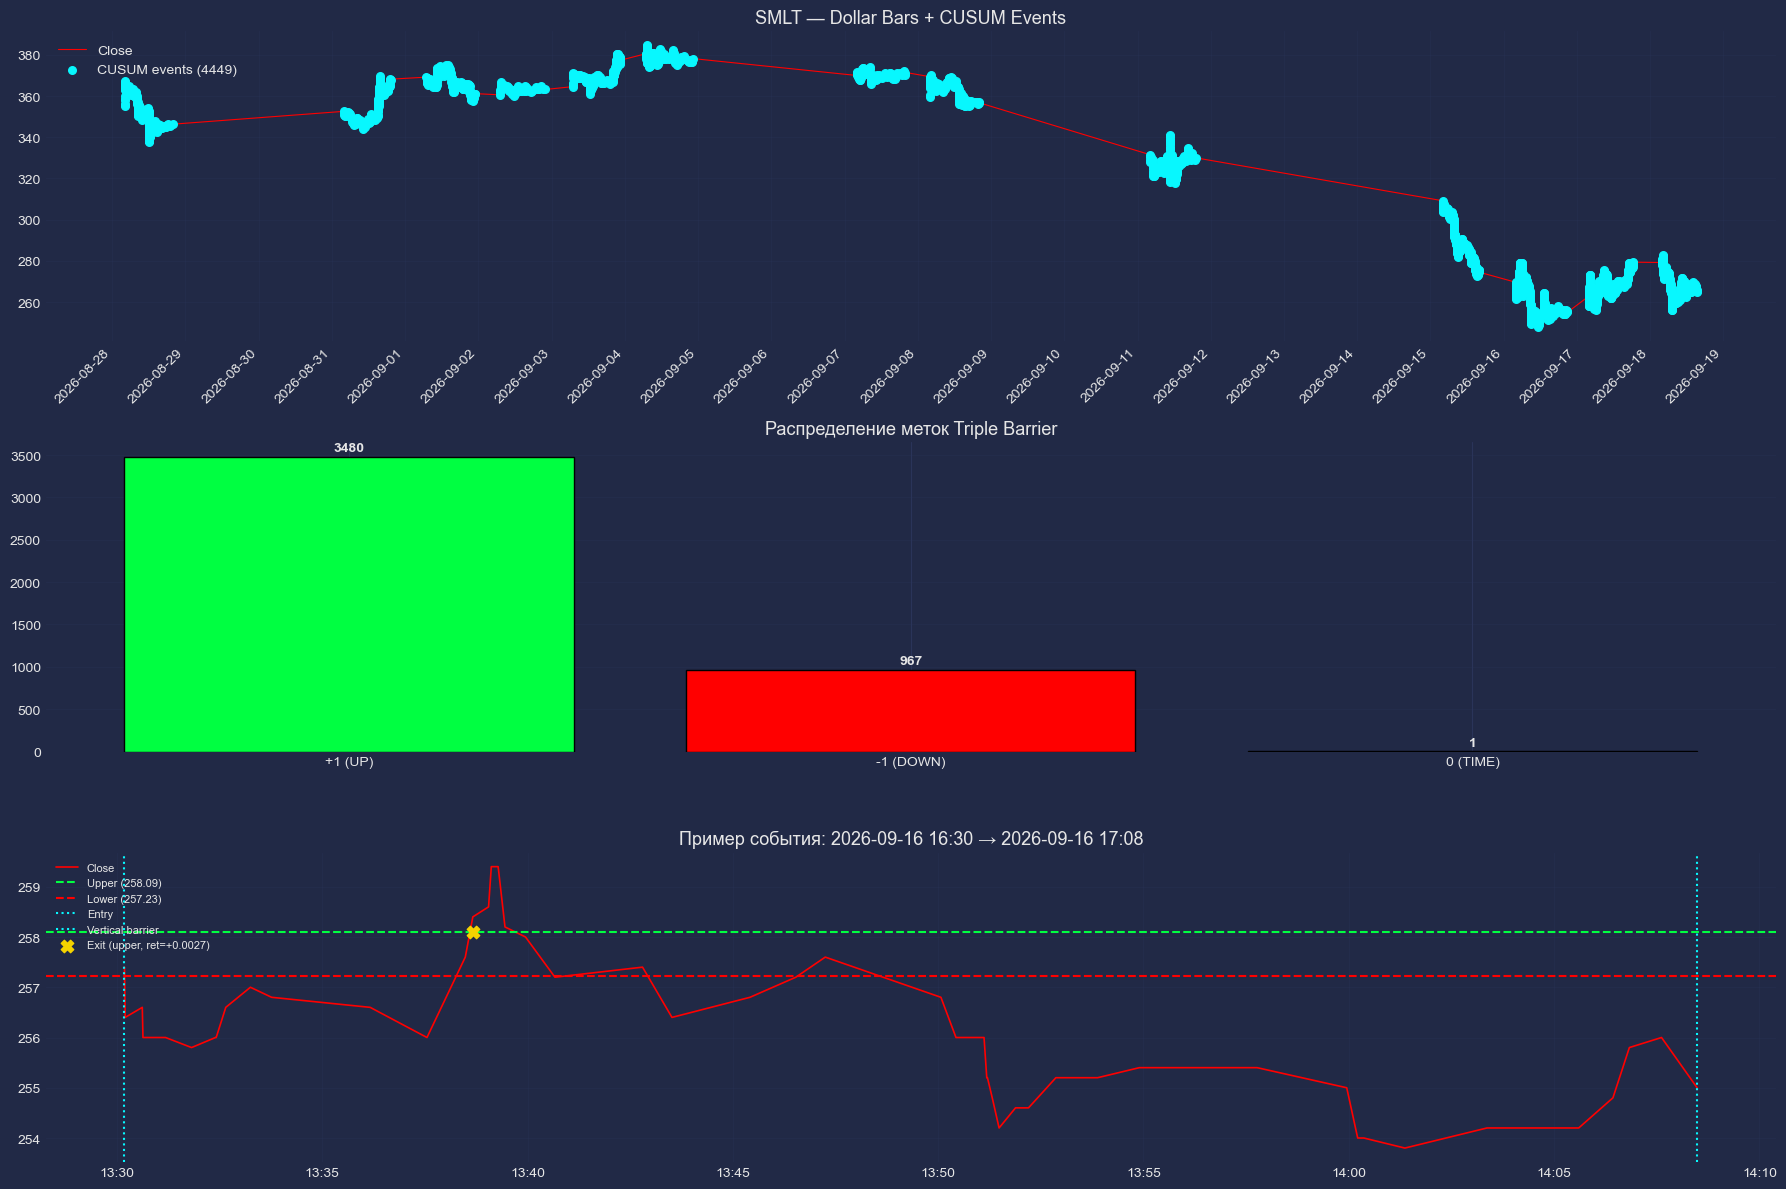

In [3]:
# ============================================================
# DOLLAR BARS + CUSUM + TRIPLE BARRIER
# ============================================================

DOLLAR_THRESHOLD = 8_000_000
CUSUM_THRESHOLD = 0.001
PT_SL = (1.6, 0.4)
VERTICAL_BARRIER = 50
TARGET_WINDOW = 50

print("=" * 70)
print(f"{TICKER} — ПОСТРОЕНИЕ DOLLAR BARS")
print("=" * 70)

# ============================================================
# 1. БЕРЕМ RAW TRADES
# ============================================================

trades = data["trades"].copy()
print(f"\nRAW TRADES: {len(trades):,} записей")
print(f"Колонки: {list(trades.columns)}")

# ============================================================
# 2. ПРОВЕРЯЕМ НЕОБХОДИМЫЕ КОЛОНКИ
# ============================================================

required_cols = ["PRICE", "QUANTITY", "VALUE", "ts"]
missing = [col for col in required_cols if col not in trades.columns]
if missing:
    raise ValueError(f"В trades.parquet отсутствуют необходимые колонки: {missing}")

# ============================================================
# 3. ПРИВОДИМ ТИПЫ
# ============================================================

trades["ts"] = pd.to_datetime(trades["ts"])
trades["PRICE"] = pd.to_numeric(trades["PRICE"], errors="coerce")
trades["QUANTITY"] = pd.to_numeric(trades["QUANTITY"], errors="coerce")
trades["VALUE"] = pd.to_numeric(trades["VALUE"], errors="coerce")

# ============================================================
# 4. УДАЛЯЕМ БИТЫЕ СДЕЛКИ
# ============================================================

before = len(trades)
trades = trades.dropna(subset=["ts", "PRICE", "QUANTITY", "VALUE"])
trades = trades[(trades["PRICE"] > 0) & (trades["QUANTITY"] > 0) & (trades["VALUE"] > 0)].copy()
after = len(trades)
print(f"\nПосле очистки: {after:,} сделок")
if before != after:
    print(f"Удалено: {before - after:,}")

# ============================================================
# 5. FORENSIC CHECK
# VALUE — реальный денежный оборот сделки.
# PRICE × QUANTITY НЕ используем как денежный оборот,
# потому что QUANTITY задан в ЛОТАХ.

price_x_quantity = (trades["PRICE"] * trades["QUANTITY"]).sum()
real_value = trades["VALUE"].sum()
print("\n" + "=" * 70)
print("TURNOVER FORENSICS")
print("=" * 70)
print(f"PRICE × QUANTITY: {price_x_quantity:,.2f} RUB")
print(f"VALUE:            {real_value:,.2f} RUB")
if price_x_quantity > 0:
    ratio = real_value / price_x_quantity
    print(f"VALUE / (PRICE × QUANTITY): {ratio:.4f}")
print("\nДля dollar bars используется именно VALUE.")

# ============================================================
# 6. ПОДГОТАВЛИВАЕМ ДАННЫЕ ДЛЯ InformationDrivenBars
# InformationDrivenBars.build_dollar() ожидает:
#     price * quantity
# Поэтому превращаем VALUE обратно в эквивалентное
# количество акций:
#     quantity_corrected = VALUE / PRICE
# Тогда:
#     PRICE × quantity_corrected
#       =
#     PRICE × (VALUE / PRICE)
#       =
#     VALUE
# Таким образом размер лота больше вообще не имеет значения.
# ============================================================

trades_for_bars = pd.DataFrame({
    "ts": trades["ts"],
    "price": trades["PRICE"],
    "quantity": trades["VALUE"] / trades["PRICE"],})
trades_for_bars = trades_for_bars.dropna(subset=["ts", "price", "quantity"])
trades_for_bars = trades_for_bars[(trades_for_bars["price"] > 0) & (trades_for_bars["quantity"] > 0)].copy()

# ============================================================
# 7. ПРОВЕРКА ПЕРЕД ПОСТРОЕНИЕМ БАРОВ
# ============================================================

reconstructed_value = (trades_for_bars["price"] * trades_for_bars["quantity"]).sum()
print("\n" + "=" * 70)
print("DOLLAR VALUE CHECK")
print("=" * 70)
print(f"Исходный VALUE:       {real_value:,.2f} RUB")
print(f"Восстановленный value:{reconstructed_value:,.2f} RUB")
relative_error = abs(reconstructed_value - real_value) / real_value
print(f"Относительная ошибка:  {relative_error:.12%}")
if relative_error > 1e-10:
    raise ValueError("КРИТИЧЕСКАЯ ОШИБКА: VALUE не восстанавливается через price × quantity.")
print("✓ VALUE корректно восстанавливается")

# ============================================================
# 8. DOLLAR BARS
# ============================================================

print("\n" + "=" * 70)
print("ПОСТРОЕНИЕ DOLLAR BARS")
print("=" * 70)
print(f"Порог: {DOLLAR_THRESHOLD:,.0f} RUB")
bar_builder = InformationDrivenBars()
dollar_bars = bar_builder.build_dollar(trades_for_bars, threshold=DOLLAR_THRESHOLD)
print(f"Получено баров: {len(dollar_bars):,}")

# ============================================================
# 9. ПРОВЕРКА ОБОРОТА DOLLAR BARS
# ============================================================

print("\n" + "=" * 70)
print("BAR FORENSICS")
print("=" * 70)
if "volume" in dollar_bars.columns:
    bars_volume = dollar_bars["volume"].sum()
    print(f"Суммарный volume bars: {bars_volume:,.2f}")
if "value" in dollar_bars.columns:
    bars_value = dollar_bars["value"].sum()
    print(f"Суммарный VALUE bars: {bars_value:,.2f}")
    print(f"Исходный VALUE:       {real_value:,.2f}")

# ============================================================
# 10. ВРЕМЕННОЙ ИНДЕКС
# ============================================================

dollar_bars["ts"] = dollar_bars["close_time"]
dollar_bars["ts"] = pd.to_datetime(dollar_bars["ts"])
if dollar_bars["ts"].dt.tz is None:
    dollar_bars["ts"] = dollar_bars["ts"].dt.tz_localize("Europe/Moscow")
dollar_bars = dollar_bars.set_index("ts").sort_index()

# ============================================================
# 11. ПЕРЕИМЕНОВАНИЕ OHLC
# ============================================================

dollar_bars = dollar_bars.rename(columns={
    "open": "OPEN",
    "high": "HIGH",
    "low": "LOW",
    "close": "CLOSE",
    "volume": "VOLUME",
})

# ============================================================
# 12. УНИКАЛЬНОСТЬ ИНДЕКСА
# ============================================================

dollar_bars = dollar_bars[~dollar_bars.index.duplicated(keep="first")]
dollar_bars = dollar_bars[~dollar_bars.index.isna()]
print(f"\nИндекс уникален: {dollar_bars.index.is_unique}")
print(f"Итого dollar bars: {len(dollar_bars):,}")

# ============================================================
# 13. CUSUM
# ============================================================

print("\n" + "=" * 70)
print("CUSUM")
print("=" * 70)
events_idx = cusum_filter(dollar_bars["CLOSE"], threshold=CUSUM_THRESHOLD)
print(f"Найдено событий до корректировки: {len(events_idx)}")

# ============================================================
# 14. СОГЛАСОВАНИЕ TIMEZONE
# ============================================================

if len(events_idx) > 0:
    if dollar_bars.index.tz is not None:
        if events_idx.tz is None:
            events_idx = events_idx.tz_localize(dollar_bars.index.tz)
        elif events_idx.tz != dollar_bars.index.tz:
            events_idx = events_idx.tz_convert(dollar_bars.index.tz)
    else:
        if events_idx.tz is not None:
            events_idx = events_idx.tz_localize(None)
    events_idx = events_idx[~events_idx.duplicated()]
    pos = dollar_bars.index.get_indexer(events_idx, method="nearest")
    events_idx = dollar_bars.index[pos]
    events_idx = events_idx[~events_idx.duplicated()]
    events_idx = events_idx.sort_values()
    print(f"После согласования: {len(events_idx)} событий")

# ============================================================
# 15. ПОДГОТОВКА К TRIPLE BARRIER
# ============================================================

bars_for_labeling = dollar_bars.rename(columns={
    "open": "OPEN",
    "high": "HIGH",
    "low": "LOW",
    "close": "CLOSE",
})

# ============================================================
# 16. TRIPLE BARRIER
# ============================================================

print("\n" + "=" * 70)
print("TRIPLE BARRIER")
print("=" * 70)
labeled = triple_barrier_labeling(
    bars=bars_for_labeling,
    events=events_idx,
    pt_sl=PT_SL,
    vertical_barrier=VERTICAL_BARRIER,
    target_window=TARGET_WINDOW,
    target_method="ewm",
)
print(f"Размечено событий: {len(labeled)}")
if not labeled.empty:
    counts = labeled["label"].value_counts()
    print("\nРаспределение меток:")
    for lbl, name, emoji in [(1, "UP (+1)", "🟢"), (-1, "DOWN (-1)", "🔴"), (0, "TIME (0)", "🟡")]:
        cnt = counts.get(lbl, 0)
        pct = 100 * cnt / len(labeled)
        print(f"{emoji} {name}: {cnt:4d} ({pct:5.1f}%)")

# ============================================================
# 17. ВИЗУАЛИЗАЦИЯ
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(18, 12))

# ------------------------------------------------------------
# График 1 — Dollar Bars + CUSUM
# ------------------------------------------------------------

ax1 = axes[0]
ax1.plot(dollar_bars.index, dollar_bars["CLOSE"], linewidth=0.8, color="C4", label="Close")
if len(events_idx) > 0:
    ax1.scatter(events_idx, dollar_bars.loc[events_idx, "CLOSE"], color="C6", s=30, zorder=5, label=f"CUSUM events ({len(events_idx)})")
ax1.set_title(f"{TICKER} — Dollar Bars + CUSUM Events", fontsize=13)
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax1.xaxis.set_major_locator(mdates.DayLocator())
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha="right")

# ------------------------------------------------------------
# График 2 — Labels
# ------------------------------------------------------------

ax2 = axes[1]
if not labeled.empty:
    colors = ["C3", "C4", "C2"]
    bars_labels = ["+1 (UP)", "-1 (DOWN)", "0 (TIME)"]
    values = [counts.get(1, 0), counts.get(-1, 0), counts.get(0, 0)]
    ax2.bar(bars_labels, values, color=colors, edgecolor="black")
    for i, v in enumerate(values):
        ax2.text(i, v + max(values) * 0.02, str(v), ha="center", fontweight="bold")
ax2.set_title("Распределение меток Triple Barrier", fontsize=13)
ax2.grid(axis="y", alpha=0.3)

# ------------------------------------------------------------
# График 3 — пример события
# ------------------------------------------------------------

ax3 = axes[2]
if not labeled.empty:
    sample = labeled.sample(1).iloc[0]
    evt_time = sample.name
    t1_time = sample["t1"]
    if not isinstance(t1_time, pd.Timestamp):
        t1_time = dollar_bars.index[t1_time] if isinstance(t1_time, int) else t1_time
    mask = (dollar_bars.index >= evt_time) & (dollar_bars.index <= t1_time)
    slice_bars = dollar_bars.loc[mask]
    ax3.plot(slice_bars.index, slice_bars["CLOSE"], linewidth=1.2, color="C4", label="Close")
    ax3.axhline(y=sample["upper"], color="C3", linestyle="--", label=f"Upper ({sample['upper']:.2f})")
    ax3.axhline(y=sample["lower"], color="C4", linestyle="--", label=f"Lower ({sample['lower']:.2f})")
    ax3.axvline(x=evt_time, color="C6", linestyle=":", label="Entry")
    ax3.axvline(x=t1_time, color="C6", linestyle=":", label="Vertical barrier")
    exit_time = sample["exit_time"]
    if not isinstance(exit_time, pd.Timestamp):
        exit_time = dollar_bars.index[exit_time] if isinstance(exit_time, int) else exit_time
    ax3.scatter(exit_time, sample["exit_price"], color="C2", s=80, zorder=5, marker="X", label=f"Exit ({sample['exit_type']}, ret={sample['ret']:+.4f})")
    ax3.set_title(f"Пример события: {evt_time.strftime('%Y-%m-%d %H:%M')} → {t1_time.strftime('%Y-%m-%d %H:%M')}", fontsize=13)
    ax3.legend(loc="upper left", fontsize=8)
    ax3.grid(True, alpha=0.3)
    ax3.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))

plt.tight_layout()
plt.show()

In [4]:
"""
Ячейка 3 (исправленная): Генерация признаков + XGBoost
=======================================================
Убираем datetime-колонки, добавляем микроструктурные признаки.
"""
TRAIN_RATIO = 0.75
print("▸ Генерация признаков...")

# Приводим колонки баров к нижнему регистру (ожидается feature-модулями)
bars_lower = dollar_bars.rename(columns={"OPEN": "open", "HIGH": "high", "LOW": "low", "CLOSE": "close", "VOLUME": "volume"})

# Микроструктурные признаки
mf = MicroFeatures(spread_window=20, volatility_window=20, intensity_window=20)
bars_with_micro = mf.build_all_features(bars_lower)

# Общие признаки (техиндикаторы, лаги, скользящие)
fb = FeatureBuilder(windows=[5, 10, 20], lags=[1, 2, 3], include_micro=False)
bars_featured = fb.build_all(bars_with_micro)
print(f"  Всего колонок в расширенных барах: {bars_featured.shape[1]}")

# Удаляем нечисловые колонки (datetime, строки и т.п.)
numeric_cols = bars_featured.select_dtypes(include=[np.number]).columns
bars_featured = bars_featured[numeric_cols]
print(f"  Из них числовых: {len(numeric_cols)}")

# Прикрепляем признаки к событиям
events_df = labeled.copy()
for col in bars_featured.columns:
    events_df[f"bar_{col}"] = events_df.index.map(
        lambda t: bars_featured.loc[t, col] if t in bars_featured.index else np.nan
    )

events_df = events_df.dropna()
print(f"  Событий с полными признаками: {len(events_df)}")

# Бинарные метки
mask_bin = events_df["label"] != 0
feature_cols = [c for c in events_df.columns if c.startswith("bar_")]
X = events_df[feature_cols]
y = events_df["label"]

X_bin = X.loc[mask_bin]
y_bin = y.loc[mask_bin].map({1: 1, -1: 0})

print(f"  Бинарных событий: {len(X_bin)} (UP: {y_bin.sum()}, DOWN: {len(y_bin) - y_bin.sum()})")
split_idx = int(len(X_bin) * TRAIN_RATIO)
X_train, X_test = X_bin.iloc[:split_idx], X_bin.iloc[split_idx:]
y_train, y_test = y_bin.iloc[:split_idx], y_bin.iloc[split_idx:]
print(f"  Train: {len(X_train)}, Test: {len(X_test)}")

▸ Генерация признаков...


  Всего колонок в расширенных барах: 75
  Из них числовых: 73
  Событий с полными признаками: 4447
  Бинарных событий: 4446 (UP: 3479, DOWN: 967)
  Train: 3334, Test: 1112


XGBoost        : Accuracy=0.7365, ROC AUC=0.5963
Random Forest  : Accuracy=0.3399, ROC AUC=0.6206


  File "C:\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


LightGBM       : Accuracy=0.7329, ROC AUC=0.5747
CatBoost       : Accuracy=0.8013, ROC AUC=0.5516

Сравнение моделей:
        Model  Accuracy  ROC AUC
Random Forest  0.339928 0.620612
      XGBoost  0.736511 0.596295
     LightGBM  0.732914 0.574662
     CatBoost  0.801259 0.551630


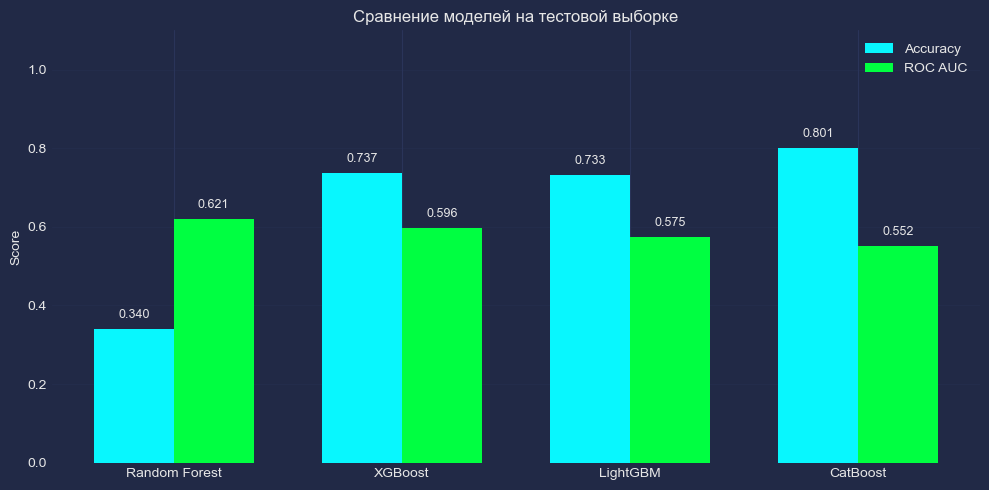

In [5]:
"""
Ячейка 4: Сравнение моделей на train/test
=========================================================
Прямое сравнение без кросс-валидации, так как данных пока мало.
"""
models = {
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, eval_metric="logloss", verbosity=0),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=13, class_weight="balanced"),
    "LightGBM": LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05, subsample=0.8, random_seed=13, verbose=0, allow_writing_files=False),}

results = []
for name, model in models.items():
    # Проверяем, что в y_train есть оба класса, иначе модель не обучится
    if len(np.unique(y_train)) < 2:
        print(f"{name:<15}: в обучающей выборке только один класс, пропускаем")
        continue
    # Обучаем на train
    model.fit(X_train, y_train)
    # Предсказываем на test
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    # Считаем метрики (только если в y_test есть оба класса)
    if len(np.unique(y_test)) < 2:
        acc = accuracy_score(y_test, y_pred)
        print(f"{name:<15}: Accuracy={acc:.4f} (ROC AUC не определён, только один класс в тесте)")
        results.append({"Model": name, "Accuracy": acc, "ROC AUC": np.nan})
        continue
    acc = accuracy_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_proba)
    results.append({"Model": name, "Accuracy": acc, "ROC AUC": roc})
    print(f"{name:<15}: Accuracy={acc:.4f}, ROC AUC={roc:.4f}")

df_res = pd.DataFrame(results).sort_values("ROC AUC", ascending=False)
print("\nСравнение моделей:")
print(df_res.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))    
x = np.arange(len(df_res))
width = 0.35
bars1 = ax.bar(x - width/2, df_res["Accuracy"], width, label="Accuracy", color="C6")
bars2 = ax.bar(x + width/2, df_res["ROC AUC"], width, label="ROC AUC", color="C3")
    
for bar in bars1:
    height = bar.get_height()
    if not np.isnan(height):
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)
    
for bar in bars2:
    height = bar.get_height()
    if not np.isnan(height):
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02, f'{height:.3f}', ha='center', va='bottom', fontsize=9)
    
ax.set_ylabel("Score")
ax.set_title("Сравнение моделей на тестовой выборке")
ax.set_xticks(x)
ax.set_xticklabels(df_res["Model"])
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis='y', alpha=0.3)
    
plt.tight_layout()
plt.show()

▶ Тестирование XGBoost...


  Сделок: 1099
  Доходность: 135.65%
  Win rate: 64.1%
  Sharpe: 3.92
  Max DD: -10.57%
  Profit Factor: 1.86

▶ Тестирование Random Forest...
  Сделок: 1099
  Доходность: -86.47%
  Win rate: 30.1%
  Sharpe: -8.63
  Max DD: -87.13%
  Profit Factor: 0.24

▶ Тестирование LightGBM...
  Сделок: 1099
  Доходность: 162.40%
  Win rate: 65.3%
  Sharpe: 4.44
  Max DD: -9.34%
  Profit Factor: 2.02

▶ Тестирование CatBoost...
  Сделок: 1099
  Доходность: 376.23%
  Win rate: 71.5%
  Sharpe: 7.78
  Max DD: -4.68%
  Profit Factor: 3.40



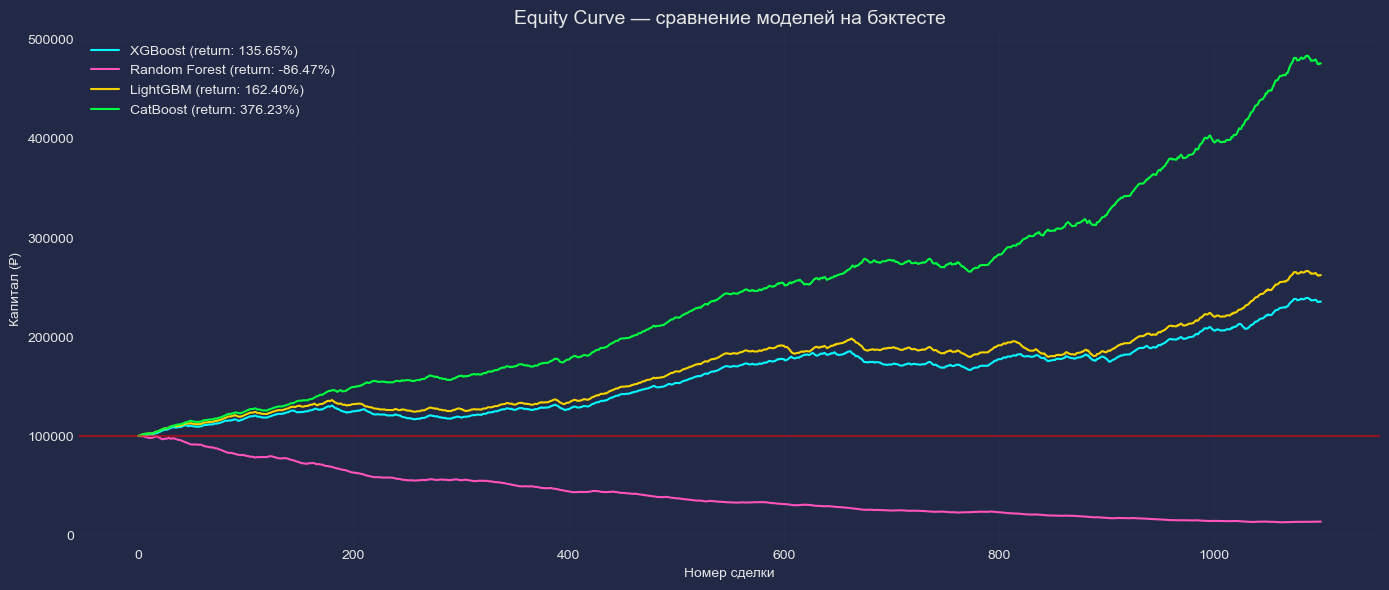


СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
       Модель  Доходность (%)    Sharpe  Max DD (%)  Win Rate (%)  Profit Factor  Сделок
      XGBoost      135.654163  3.915264  -10.570805     64.058235       1.857562    1099
Random Forest      -86.465952 -8.632579  -87.128382     30.118289       0.239461    1099
     LightGBM      162.402989  4.436282   -9.344182     65.332120       2.016849    1099
     CatBoost      376.232251  7.776630   -4.680860     71.519563       3.399276    1099


In [7]:
"""
Ячейка 5: Бэктест моделей (реалистичная торговая симуляция)
===============================================================
Реалистичный бэктест с учётом:
- Входа по сигналу модели
- Выхода по SL/TP (барьеры Triple Barrier)
- Выхода по смене сигнала (reverse) по рыночной цене
- Принудительного закрытия в 23:00
- Учёт комиссии и проскальзывания
- Реинвестирования прибыли
"""

models = {
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, eval_metric="logloss", verbosity=0),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=13, class_weight="balanced"),
    "LightGBM": LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=13, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05, subsample=0.8, random_seed=13, verbose=0, allow_writing_files=False),}

# Параметры торговли
INITIAL_CAPITAL = 100000
COMMISSION = 0.0006     # 0.06%
SLIPPAGE = 0.0001       # 0.01%

# Восстанавливаем цены
test_times = X_test.index
bar_close = dollar_bars["CLOSE"]
labeled_test = labeled.loc[test_times]

def run_backtest(model, X_train, y_train, X_test, y_test, labeled_test, bar_close,
                 initial_capital=INITIAL_CAPITAL, commission=COMMISSION, slippage=SLIPPAGE):
    """
    Реалистичный бэктест с реинвестированием.
    """
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    preds_original = np.array([-1 if p == 0 else 1 for p in preds])

    capital = initial_capital
    equity = [initial_capital]
    trades = []
    position = None  # {'side': 'long'/'short', 'entry': цена, 'entry_time': время}

    for i, (evt_time, row) in enumerate(labeled_test.iterrows()):
        signal = preds_original[i]
        if signal == 0:
            continue

        # ---- Принудительное закрытие в 23:00 ----
        if position is not None and evt_time.hour >= 23:
            close_price = bar_close.loc[evt_time]
            if position['side'] == 'long':
                pnl_pct = (close_price / position['entry'] - 1) - commission
            else:
                pnl_pct = (position['entry'] / close_price - 1) - commission
            pnl = pnl_pct * capital
            capital += pnl
            trades.append({
                'entry_time': position['entry_time'],
                'exit_time': evt_time,
                'side': position['side'],
                'entry': position['entry'],
                'exit': close_price,
                'pnl': pnl,
                'pnl_pct': pnl_pct,
                'exit_reason': 'forced_close_23'
            })
            equity.append(capital)
            position = None
            continue

        # ---- Если позиция открыта и сигнал сменился (reverse) ----
        if position is not None and signal != (1 if position['side'] == 'long' else -1):
            close_price = bar_close.loc[evt_time]
            if position['side'] == 'long':
                pnl_pct = (close_price / position['entry'] - 1) - commission
            else:
                pnl_pct = (position['entry'] / close_price - 1) - commission
            pnl = pnl_pct * capital
            capital += pnl
            trades.append({
                'entry_time': position['entry_time'],
                'exit_time': evt_time,
                'side': position['side'],
                'entry': position['entry'],
                'exit': close_price,
                'pnl': pnl,
                'pnl_pct': pnl_pct,
                'exit_reason': 'reverse_signal'
            })
            equity.append(capital)
            position = None

        # ---- Если позиция открыта и достигнут барьер SL/TP ----
        if position is not None:
            exit_type = row.get('exit_type')
            if exit_type in ('upper', 'lower', 'vertical'):
                close_price = row['exit_price']
                if position['side'] == 'long':
                    pnl_pct = (close_price / position['entry'] - 1) - commission
                else:
                    pnl_pct = (position['entry'] / close_price - 1) - commission
                pnl = pnl_pct * capital
                capital += pnl
                trades.append({
                    'entry_time': position['entry_time'],
                    'exit_time': row['exit_time'],
                    'side': position['side'],
                    'entry': position['entry'],
                    'exit': close_price,
                    'pnl': pnl,
                    'pnl_pct': pnl_pct,
                    'exit_reason': exit_type
                })
                equity.append(capital)
                position = None

        # ---- Открытие новой позиции ----
        if position is None and evt_time.hour < 21:
            entry_price = bar_close.loc[evt_time]
            # Учитываем проскальзывание при входе
            if signal == 1:
                entry_price *= (1 + slippage)
                side = 'long'
            else:
                entry_price *= (1 - slippage)  # для short цена входа выше
                side = 'short'
            position = {
                'side': side,
                'entry': entry_price,
                'entry_time': evt_time
            }

    # ---- Закрываем последнюю позицию ----
    if position is not None:
        last_row = labeled_test.iloc[-1]
        close_price = bar_close.loc[last_row.name]
        if position['side'] == 'long':
            pnl_pct = (close_price / position['entry'] - 1) - commission
        else:
            pnl_pct = (position['entry'] / close_price - 1) - commission
        pnl = pnl_pct * capital
        capital += pnl
        trades.append({
            'entry_time': position['entry_time'],
            'exit_time': last_row.name,
            'side': position['side'],
            'entry': position['entry'],
            'exit': close_price,
            'pnl': pnl,
            'pnl_pct': pnl_pct,
            'exit_reason': 'last'
        })
        equity.append(capital)

    # ---- Расчёт метрик ----
    if trades:
        df_trades = pd.DataFrame(trades)
        total_return = (capital / initial_capital - 1) * 100
        returns = df_trades['pnl_pct']
        sharpe = (returns.mean() / returns.std() * np.sqrt(252)) if returns.std() != 0 else 0
        equity_curve = np.array(equity)
        peak = np.maximum.accumulate(equity_curve)
        drawdown = (equity_curve - peak) / peak
        max_drawdown = drawdown.min() * 100
        win_rate = (df_trades['pnl'] > 0).mean() * 100
        profit_factor = (df_trades[df_trades['pnl'] > 0]['pnl'].sum() /
                         abs(df_trades[df_trades['pnl'] < 0]['pnl'].sum())) if (df_trades['pnl'] < 0).any() else np.inf
        df_trades['trade_num'] = range(1, len(df_trades) + 1)
    else:
        total_return = 0
        sharpe = 0
        max_drawdown = 0
        win_rate = 0
        profit_factor = 0
        df_trades = pd.DataFrame()
        equity_curve = np.array([initial_capital])

    return {
        'total_return': total_return,
        'sharpe': sharpe,
        'max_drawdown': max_drawdown,
        'win_rate': win_rate,
        'profit_factor': profit_factor,
        'trades': df_trades,
        'equity_curve': equity_curve
    }


# ---- Запуск бэктеста для всех моделей ----
backtest_results = {}

for name, model in models.items():
    print(f"▶ Тестирование {name}...")
    result = run_backtest(
        model, X_train, y_train, X_test, y_test,
        labeled_test, bar_close
    )
    backtest_results[name] = result

    if not result['trades'].empty:
        df_trades = result['trades']
        print(f"  Сделок: {len(df_trades)}")
        print(f"  Доходность: {result['total_return']:.2f}%")
        print(f"  Win rate: {result['win_rate']:.1f}%")
        print(f"  Sharpe: {result['sharpe']:.2f}")
        print(f"  Max DD: {result['max_drawdown']:.2f}%")
        print(f"  Profit Factor: {result['profit_factor']:.2f}")
    else:
        print("  ❌ Нет сделок")
    print()

# ---- График Equity кривых ----
fig, ax = plt.subplots(figsize=(14, 6))

for name, res in backtest_results.items():
    if res['total_return'] != 0:
        ax.plot(res['equity_curve'], label=f"{name} (return: {res['total_return']:.2f}%)")

ax.axhline(y=INITIAL_CAPITAL, color='C4', alpha=0.5)
ax.set_title("Equity Curve — сравнение моделей на бэктесте", fontsize=14)
ax.set_xlabel("Номер сделки")
ax.set_ylabel("Капитал (₽)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Итоговая таблица ----
print("\n" + "="*70)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("="*70)
summary = pd.DataFrame({
    'Модель': list(backtest_results.keys()),
    'Доходность (%)': [res['total_return'] for res in backtest_results.values()],
    'Sharpe': [res['sharpe'] for res in backtest_results.values()],
    'Max DD (%)': [res['max_drawdown'] for res in backtest_results.values()],
    'Win Rate (%)': [res['win_rate'] for res in backtest_results.values()],
    'Profit Factor': [res['profit_factor'] for res in backtest_results.values()],
    'Сделок': [len(res['trades']) for res in backtest_results.values()]
})
print(summary.to_string(index=False))

# Оптимизация

In [ ]:
TICKER = "SMLT"
N_TRIALS = 30
STUDY_NAME = f"param_optimization_sharpe_{TICKER}_mark_42"
TIMEOUT = 10800
TRAIN_RATIO = 0.8
PT_SL = (1.0, 1.0)
CUSUM_THRESHOLD = 0.002
VERTICAL_BARRIER = 45
TARGET_WINDOW = 50
DOLLAR_THRESHOLD = 8_000_000

# =============================================================================
# 1. ЗАГРУЗКА ИСТОРИИ
# =============================================================================

def get_available_dates(ticker: str) -> list:
    """
    Автоматически находит все доступные даты для тикера.

    Сканирует:
        history/realtime/{ticker}/{date}
        history/supercandles/{ticker}/{date}
    """
    dates = set()
    base_realtime = ROOT / "for_ml" / "storage" / "history" / "realtime" / ticker
    if base_realtime.exists():
        for date_dir in base_realtime.iterdir():
            if date_dir.is_dir():
                dates.add(date_dir.name)
    base_supercandles = ROOT / "for_ml" / "storage" / "history" / "supercandles" / ticker
    if base_supercandles.exists():
        for date_dir in base_supercandles.iterdir():
            if date_dir.is_dir():
                dates.add(date_dir.name)
    return sorted(list(dates))

def load_history(ticker: str) -> dict:
    """
    Загружает все сырые данные за все доступные даты.

    Структура:

    history/
        realtime/
            TICKER/
                DATE/
                    candles.parquet
                    trades.parquet
                    orderbook.parquet

        supercandles/
            TICKER/
                DATE/
                    tradestats.parquet
                    obstats.parquet
                    orderstats.parquet
    """
    result = {"candles": [], "trades": [], "orderbook": [], "tradestats": [], "obstats": [], "orderstats": []}
    base_realtime = ROOT / "for_ml" / "storage" / "history" / "realtime"
    base_supercandles = ROOT / "for_ml" / "storage" / "history" / "supercandles"
    dates = get_available_dates(ticker)
    for date in dates:
        rt_dir = base_realtime / ticker / date
        for key in ["candles", "trades", "orderbook"]:
            filepath = rt_dir / f"{key}.parquet"
            if filepath.exists():
                try:
                    df = pd.read_parquet(filepath)
                    df["date"] = date
                    result[key].append(df)
                except Exception as e:
                    logger.error(f"Ошибка загрузки {filepath}: {e}")
        sc_dir = base_supercandles / ticker / date
        for key in ["tradestats", "obstats", "orderstats"]:
            filepath = sc_dir / f"{key}.parquet"
            if filepath.exists():
                try:
                    df = pd.read_parquet(filepath)
                    df["date"] = date
                    result[key].append(df)
                except Exception as e:
                    logger.error(f"Ошибка загрузки {filepath}: {e}")
    for key in result:
        if result[key]:
            result[key] = pd.concat(result[key], ignore_index=True)
        else:
            result[key] = pd.DataFrame()
    return result

# =============================================================================
# 2. ЗАГРУЗКА
# =============================================================================
print(f"ЗАГРУЗКА ДАННЫХ: {TICKER}")
data = load_history(TICKER)

# =============================================================================
# 3. TIMESTAMP
# =============================================================================
for key, df in data.items():
    if not df.empty and "ts" in df.columns:
        df["ts"] = pd.to_datetime(df["ts"], utc=True).dt.tz_convert("Europe/Moscow")

# =============================================================================
# 4. СТАТИСТИКА ЗАГРУЗКИ
# =============================================================================
print("ЗАГРУЖЕНО:")
for key, df in data.items():
    print(f"  {key:<12}: {len(df):>12,} записей")
if not data["candles"].empty:
    print()
    print(f"Диапазон candles: {data['candles']['ts'].min()} → {data['candles']['ts'].max()}")
available_dates = get_available_dates(TICKER)
print()
print(f"Доступные даты ({len(available_dates)}):")
for date in available_dates:
    print(f"  {date}")

# =============================================================================
# 5. FORENSIC CHECK
# =============================================================================
print(f"{TICKER} DATA FORENSICS")
trades_raw = data["trades"].copy()
candles_raw = data["candles"].copy()

# -----------------------------------------------------------------------------
# SHAPES
# -----------------------------------------------------------------------------
print("1. SHAPES")
print(f"trades : {trades_raw.shape}")
print(f"candles: {candles_raw.shape}")
print()
print("TRADES COLUMNS:")
print(list(trades_raw.columns))
print()
print("CANDLES COLUMNS:")
print(list(candles_raw.columns))

# -----------------------------------------------------------------------------
# SAMPLE
# -----------------------------------------------------------------------------

print()
print("2. TRADES SAMPLE")
print("-" * 80)
print(trades_raw.head(10).to_string())
print()
print("3. CANDLES SAMPLE")
print("-" * 80)
print(candles_raw.head(10).to_string())

# =============================================================================
# 6. FORENSIC TURNOVER
# =============================================================================

print()
print("4. TURNOVER COMPARISON")
print("-" * 80)

required_trade_columns = ["PRICE", "QUANTITY", "VALUE"]
missing = [c for c in required_trade_columns if c not in trades_raw.columns]
if missing:
    raise ValueError(f"В trades отсутствуют обязательные колонки: {missing}")
for col in ["PRICE", "QUANTITY", "VALUE"]:
    trades_raw[col] = pd.to_numeric(trades_raw[col], errors="coerce")
trades_check = trades_raw.dropna(subset=["PRICE", "QUANTITY", "VALUE"]).copy()
trades_check["price_x_quantity"] = trades_check["PRICE"] * trades_check["QUANTITY"]
trades_check["implied_lot_size"] = trades_check["VALUE"] / trades_check["price_x_quantity"]

# -----------------------------------------------------------------------------
# Основная статистика
# -----------------------------------------------------------------------------
total_quantity = trades_check["QUANTITY"].sum()
price_x_quantity = trades_check["price_x_quantity"].sum()
total_value = trades_check["VALUE"].sum()
print(f"TRADES Rows:                    {len(trades_check):,}")
print(f"Total QUANTITY (lots):          {total_quantity:,.0f}")
print(f"PRICE × QUANTITY:               {price_x_quantity:,.2f}")
print(f"VALUE:                          {total_value:,.2f}")

# -----------------------------------------------------------------------------
# IMPLIED LOT SIZE
# -----------------------------------------------------------------------------

lot_size_median = trades_check["implied_lot_size"].replace([np.inf, -np.inf], np.nan).dropna().median()
lot_size_mean = trades_check["implied_lot_size"].replace([np.inf, -np.inf], np.nan).dropna().mean()
lot_size_unique = trades_check["implied_lot_size"].replace([np.inf, -np.inf], np.nan).round(6).value_counts().head(10)
print()
print(f"Implied LOT_SIZE median:        {lot_size_median:.6f}")
print(f"Implied LOT_SIZE mean:          {lot_size_mean:.6f}")
print()
print("Наиболее частые значения LOT_SIZE:")
print(lot_size_unique.to_string())

# =============================================================================
# 7. ПРОВЕРКА VALUE
# =============================================================================

print()
print("5. VALUE CONSISTENCY CHECK")
print("-" * 80)

expected_value = trades_check["PRICE"] * trades_check["QUANTITY"] * lot_size_median
relative_error = (trades_check["VALUE"] - expected_value).abs() / trades_check["VALUE"].replace(0, np.nan)
print(f"Median LOT_SIZE:                {lot_size_median:g}")
print(f"Median relative error:          {relative_error.median():.8f}")
print(f"Max relative error:             {relative_error.max():.8f}")

# -----------------------------------------------------------------------------
# Если ошибка большая — останавливаемся.
# -----------------------------------------------------------------------------

if pd.notna(relative_error.median()) and relative_error.median() > 1e-6:
    print()
    print("⚠️ ВНИМАНИЕ:")
    print("VALUE не выглядит как PRICE × QUANTITY × " f"{lot_size_median:g}")
    print("Проверяем структуру данных вручную.")

# =============================================================================
# 8. CANDLE TURNOVER
# =============================================================================

print()
print("6. CANDLE TURNOVER")
print("-" * 80)

if not candles_raw.empty:
    if "volume" in candles_raw.columns:
        candle_volume = pd.to_numeric(candles_raw["volume"], errors="coerce").sum()
    else:
        candle_volume = np.nan
    if "value" in candles_raw.columns:
        candle_value = pd.to_numeric(candles_raw["value"], errors="coerce").sum()
    else:
        candle_value = np.nan
    print(f"1-MIN CANDLES Rows:             {len(candles_raw):,}")
    print(f"Total VOLUME:                   {candle_volume:,.2f}")
    print(f"Total candle VALUE:             {candle_value:,.2f}")
    print()
    if pd.notna(candle_value) and total_value > 0:
        print(f"Candle VALUE / Trades VALUE:   {candle_value / total_value:.4f}")

# =============================================================================
# 9. ГЛАВНЫЙ ВЫВОД FORENSICS
# =============================================================================

print()
print("=" * 80)
print("FORENSIC CONCLUSION")
print("=" * 80)
print(f"Ticker:                         {TICKER}")
print(f"Inferred LOT_SIZE:             {lot_size_median:g}")
print(f"Trades VALUE:                   {total_value:,.2f}")
print(f"PRICE × QUANTITY:              {price_x_quantity:,.2f}")
if price_x_quantity != 0:
    print(f"VALUE / (PRICE×QUANTITY):      {total_value / price_x_quantity:.4f}")
print()
print("✅ Для InformationDrivenBars используем VALUE.")
print("❌ QUANTITY больше НЕ используется как денежный объём.")
print("=" * 80)

# =============================================================================
# 10. ПОДГОТАВЛИВАЕМ ДАННЫЕ ДЛЯ InformationDrivenBars
print("ПОДГОТАВЛИВАЕМ ДАННЫЕ ДЛЯ InformationDrivenBars")
trades = data["trades"].copy()

# -----------------------------------------------------------------------------
# Нормализуем названия
# -----------------------------------------------------------------------------

col_map = {}
for col in trades.columns:
    col_upper = col.upper()
    if col_upper in ["PRICE", "TRADEPRICE"]:
        col_map[col] = "price"
    elif col_upper in ["QUANTITY", "VOLUME"]:
        col_map[col] = "quantity"
    elif col_upper == "VALUE":
        col_map[col] = "value"
if col_map:
    trades = trades.rename(columns=col_map)

# -----------------------------------------------------------------------------
# Проверяем обязательные колонки
# -----------------------------------------------------------------------------

required = ["price", "quantity", "value", "ts"]
missing = [col for col in required if col not in trades.columns]
if missing:
    raise ValueError("Для dollar bars отсутствуют колонки: " f"{missing}")

# -----------------------------------------------------------------------------
# Numeric
# -----------------------------------------------------------------------------

for col in ["price", "quantity", "value"]:
    trades[col] = pd.to_numeric(trades[col], errors="coerce")

# -----------------------------------------------------------------------------
# Timestamp
# -----------------------------------------------------------------------------

trades["ts"] = pd.to_datetime(trades["ts"], utc=True, errors="coerce")
trades["ts"] = trades["ts"].dt.tz_convert("Europe/Moscow")
trades = trades.dropna(subset=["price", "quantity", "value", "ts"])
trades = trades[(trades["price"] > 0) & (trades["value"] >= 0)]
trades["quantity_for_bars"] = trades["value"] / trades["price"]

# -----------------------------------------------------------------------------
# Проверяем
# -----------------------------------------------------------------------------

trades["reconstructed_value"] = trades["price"] * trades["quantity_for_bars"]
check_error = (trades["reconstructed_value"] - trades["value"]).abs()
print()
print(f"Исходный QUANTITY (лоты) sum:   {trades['quantity'].sum():,.0f}")
print(f"VALUE sum:                      {trades['value'].sum():,.2f}")
print(f"Reconstructed VALUE sum:        {trades['reconstructed_value'].sum():,.2f}")
print(f"Max reconstruction error:       {check_error.max():.10f}")

# -----------------------------------------------------------------------------
# Финальная колонка quantity
trades["quantity"] = trades["quantity_for_bars"]
trades_for_bars = trades[["ts", "price", "quantity"]].copy()
trades_for_bars["turnover_check"] = trades_for_bars["price"] * trades_for_bars["quantity"]
print()
print("Проверка первых 5 сделок:")
print(trades[["price", "quantity", "value", "quantity_for_bars", "reconstructed_value"]].head().to_string(index=False))
print()
print("✅ Данные для InformationDrivenBars готовы.")
print(f"Количество сделок: {len(trades_for_bars):,}")
print(f"Реальный turnover: {trades_for_bars['turnover_check'].sum():,.2f} RUB")

# =============================================================================
# 12. СОХРАНЯЕМ ГОТОВЫЕ TRADES
print("Пример данных, которые реально пойдут в InformationDrivenBars:")
print(trades_for_bars.head(10).to_string(index=False))

# =============================================================================
# 13. ПЕРВИЧНАЯ ПРОВЕРКА DOLLAR BARS
# =============================================================================

print()
print("=" * 80)
print("ПЕРВИЧНАЯ ПРОВЕРКА InformationDrivenBars")
print("=" * 80)

bar_builder = InformationDrivenBars()
test_dollar_bars = bar_builder.build_dollar(trades_for_bars[["ts", "price", "quantity"]].copy(), threshold=DOLLAR_THRESHOLD)
print()
print(f"Threshold:                     {DOLLAR_THRESHOLD:,.0f} RUB")
print(f"Получено dollar bars:           {len(test_dollar_bars):,}")
if len(test_dollar_bars) > 0:
    print()
    print(test_dollar_bars.head().to_string())

# =============================================================================
# 14. OPTUNA OBJECTIVE
# =============================================================================

def objective(trial):
    # -------------------------------------------------------------------------
    # ПАРАМЕТРЫ OPTUNA
    # -------------------------------------------------------------------------
    dollar_threshold = trial.suggest_int("dollar_threshold", 3, 10) * 1_000_000
    tp_mult = trial.suggest_float("tp_mult", 0.5, 3.0, step=0.1)
    sl_mult = trial.suggest_float("sl_mult", 0.3, 2.0, step=0.1)
    cusum_threshold = trial.suggest_float("cusum_threshold", 0.001, 0.005, step=0.0005)
    vertical_barrier = trial.suggest_int("vertical_barrier", 10, 50, step=5)
    target_window = trial.suggest_int("target_window", 25, 75, step=5)

    try:
        # =====================================================================
        # 1. TRADES
        trades_prep = trades_for_bars[["ts", "price", "quantity"]].copy()
        trades_prep["ts"] = pd.to_datetime(trades_prep["ts"])
        trades_prep = trades_prep.dropna(subset=["price", "quantity"])
        # =====================================================================
        # 2. DOLLAR BARS
        # =====================================================================
        bar_builder = InformationDrivenBars()
        dollar_bars = bar_builder.build_dollar(trades_prep, threshold=dollar_threshold)
        if len(dollar_bars) < 20:
            return -np.inf
        # =====================================================================
        # 3. TIMESTAMP
        # =====================================================================
        dollar_bars["ts"] = dollar_bars["close_time"]
        dollar_bars["ts"] = pd.to_datetime(dollar_bars["ts"])
        if dollar_bars["ts"].dt.tz is None:
            dollar_bars["ts"] = dollar_bars["ts"].dt.tz_localize("Europe/Moscow")
        dollar_bars = dollar_bars.set_index("ts").sort_index()

        # =====================================================================
        # 4. NORMALIZE COLUMN NAMES
        # =====================================================================
        dollar_bars = dollar_bars.rename(columns={"open": "OPEN", "high": "HIGH", "low": "LOW", "close": "CLOSE", "volume": "VOLUME"})

        # =====================================================================
        # 5. INDEX CLEANUP
        # =====================================================================
        dollar_bars = dollar_bars[~dollar_bars.index.duplicated(keep="first")]
        dollar_bars = dollar_bars[~dollar_bars.index.isna()]

        # =====================================================================
        # 6. CUSUM
        # =====================================================================
        events_idx = cusum_filter(dollar_bars["CLOSE"], threshold=cusum_threshold)
        if len(events_idx) == 0:
            return -np.inf
        # =====================================================================
        # 7. TIMEZONE ALIGNMENT
        # =====================================================================
        if dollar_bars.index.tz is not None:
            if events_idx.tz is None:
                events_idx = events_idx.tz_localize(dollar_bars.index.tz)
            elif events_idx.tz != dollar_bars.index.tz:
                events_idx = events_idx.tz_convert(dollar_bars.index.tz)
        else:
            if events_idx.tz is not None:
                events_idx = events_idx.tz_localize(None)

        # =====================================================================
        # 8. EVENT CLEANUP
        # =====================================================================
        events_idx = events_idx[~events_idx.duplicated()]

        # =====================================================================
        # 9. MAP EVENTS TO NEAREST BAR
        # =====================================================================
        pos = dollar_bars.index.get_indexer(events_idx, method="nearest")
        pos = pos[pos >= 0]
        events_idx = dollar_bars.index[pos]
        events_idx = events_idx[~events_idx.duplicated()]
        events_idx = events_idx.sort_values()
        if len(events_idx) < 5:
            return -np.inf

        # =====================================================================
        # 10. TRIPLE BARRIER
        # =====================================================================
        labeled = triple_barrier_labeling(
            bars=dollar_bars,
            events=events_idx,
            pt_sl=(tp_mult, sl_mult),
            vertical_barrier=vertical_barrier,
            target_window=target_window,
            target_method="ewm",)
        if len(labeled) < 30:
            return -np.inf

        # =====================================================================
        # 11. FEATURES
        # =====================================================================
        bars_lower = dollar_bars.rename(columns={"OPEN": "open", "HIGH": "high", "LOW": "low", "CLOSE": "close", "VOLUME": "volume"})
        mf = MicroFeatures(spread_window=20, volatility_window=20, intensity_window=20)
        bars_with_micro = mf.build_all_features(bars_lower)
        fb = FeatureBuilder(windows=[5, 10, 20], lags=[1, 2, 3], include_micro=False)
        bars_featured = fb.build_all(bars_with_micro)

        # =====================================================================
        # 12. NUMERIC FEATURES
        # =====================================================================
        numeric_cols = bars_featured.select_dtypes(include=[np.number]).columns
        bars_featured = bars_featured[numeric_cols]

        # =====================================================================
        # 13. EVENTS DATAFRAME
        # =====================================================================
        events_df = labeled.copy()
        bars_at_events = bars_featured.reindex(events_df.index)
        bars_at_events.columns = [f"bar_{col}" for col in bars_at_events.columns]
        events_df = pd.concat([events_df, bars_at_events], axis=1)
        events_df = events_df.dropna()
        if len(events_df) < 30:
            return -np.inf

        # =====================================================================
        # 14. BINARY LABELS
        # =====================================================================
        mask_bin = events_df["label"] != 0
        feature_cols = [c for c in events_df.columns if c.startswith("bar_")]
        X = events_df[feature_cols]
        y = events_df["label"]
        X_bin = X.loc[mask_bin]
        y_bin = y.loc[mask_bin].map({1: 1, -1: 0})
        if len(X_bin) < 30:
            return -np.inf

        # =====================================================================
        # 15. TRAIN / TEST
        # =====================================================================
        split_idx = int(len(X_bin) * TRAIN_RATIO)
        X_train = X_bin.iloc[:split_idx]
        X_test = X_bin.iloc[split_idx:]
        y_train = y_bin.iloc[:split_idx]
        y_test = y_bin.iloc[split_idx:]

        # =====================================================================
        # 16. MODEL
        # =====================================================================
        model = CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05, subsample=0.8, random_seed=13, verbose=0)
        model.fit(X_train, y_train)

        # =====================================================================
        # 17. BACKTEST
        # =====================================================================
        result = run_backtest(model, X_train, y_train, X_test, y_test, labeled.loc[X_test.index], dollar_bars["CLOSE"])

        # =====================================================================
        # 18. METRICS
        # =====================================================================
        sharpe = result["total_return"] # Sharpe для стабильности, total_return для максимизации прибыли
        if np.isnan(sharpe):
            sharpe = -np.inf
        trial.set_user_attr("total_return", result["total_return"])
        trial.set_user_attr("max_drawdown", result["max_drawdown"])
        trial.set_user_attr("win_rate", result["win_rate"])
        trial.set_user_attr("n_trades", len(result["trades"]))
        return sharpe

    except Exception as e:
        print()
        print(f"[Trial {trial.number}] ERROR:")
        print(repr(e))
        import traceback
        traceback.print_exc()
        return -np.inf

# =============================================================================
# 19. ЗАПУСК OPTUNA
# =============================================================================
print(f"ОПТИМИЗАЦИЯ ПАРАМЕТРОВ: {TICKER}")
print(f"Модель: RandomForest {TICKER}")
print(f"Испытаний: {N_TRIALS}")
print(f"Таймаут: {TIMEOUT} сек")
print(f"Train ratio: {TRAIN_RATIO}")
print("Dollar turnover: VALUE")
print("=" * 80)

study = optuna.create_study(direction="maximize", study_name=STUDY_NAME, sampler=optuna.samplers.TPESampler(seed=13))
optuna.logging.set_verbosity(optuna.logging.WARNING)

with tqdm(total=N_TRIALS, desc="Оптимизация") as pbar:
    def callback(study, trial):
        pbar.update(1)
        if trial.value is not None and trial.value > -np.inf:
            pbar.set_postfix({"Sharpe": f"{study.best_value:.3f}", "Dollar": f'{study.best_params["dollar_threshold"]}M'})
    study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT, callbacks=[callback], show_progress_bar=False)

# =============================================================================
# 20. ИТОГИ
# =============================================================================
print(f"РЕЗУЛЬТАТ OPTUNA: {TICKER}")

if study.best_value > -np.inf:
    best_params = study.best_params
    best_trial = study.best_trial
    # -------------------------------------------------------------------------
    # PARAMS
    # -------------------------------------------------------------------------
    print("✅ ЛУЧШИЕ ПАРАМЕТРЫ")
    print(f"DOLLAR_THRESHOLD = {best_params['dollar_threshold'] * 1_000_000:,}")
    print(f"TP_MULT = {best_params['tp_mult']:.1f}%")
    print(f"SL_MULT = {best_params['sl_mult']:.1f}%")
    print(f"CUSUM_THRESHOLD = {best_params['cusum_threshold']:.4f}")
    print(f"VERTICAL_BARRIER = {best_params['vertical_barrier']}")
    print(f"TARGET_WINDOW = {best_params['target_window']}")

    # -------------------------------------------------------------------------
    # METRICS
    # -------------------------------------------------------------------------
    print()
    print(f"Sharpe Ratio: {best_trial.value:.3f}")
    tr = best_trial.user_attrs.get("total_return")
    if tr is not None:
        print(f"Доходность: {tr:.2f}%")
    dd = best_trial.user_attrs.get("max_drawdown")
    if dd is not None:
        print(f"Max Drawdown: {dd:.2f}%")
    wr = best_trial.user_attrs.get("win_rate")
    if wr is not None:
        print(f"Win Rate: {wr:.1f}%")
    nt = best_trial.user_attrs.get("n_trades")
    if nt is not None:
        print(f"Сделок: {nt}")
else:
    print()
    print("❌ Оптимизация не нашла валидных параметров.")

# =============================================================================
# 21. ФИНАЛЬНЫЙ SANITY CHECK
# =============================================================================

print()
print("=" * 80)
print("FINAL SANITY CHECK")
print("=" * 80)
print(f"TICKER:                        {TICKER}")
print(f"LOT_SIZE:                      {lot_size_median:g}")
print(f"RAW QUANTITY (lots):           {trades_raw['QUANTITY'].sum():,.0f}")
print(f"RAW VALUE:                     {trades_raw['VALUE'].sum():,.2f}")
print(f"BAR INPUT TURNOVER:            {trades_for_bars['turnover_check'].sum():,.2f}")
print()
print("InformationDrivenBars получает:")
print("    price     = PRICE")
print("    quantity  = VALUE / PRICE")
print()
print("Следовательно:")
print("    price × quantity = VALUE")
print()
print("✅ LOT_SIZE больше не ломает долларовые бары.")
print("=" * 80)

ЗАГРУЗКА ДАННЫХ: SMLT
ЗАГРУЖЕНО:
  candles     :       11,058 записей
  trades      :    1,102,732 записей
  orderbook   :          240 записей
  tradestats  :        2,219 записей
  obstats     :        2,170 записей
  orderstats  :        2,240 записей

Диапазон candles: 2026-08-28 06:59:00+03:00 → 2026-09-17 21:19:00+03:00

Доступные даты (12):
  2026-08-28
  2026-08-31
  2026-09-01
  2026-09-02
  2026-09-03
  2026-09-04
  2026-09-07
  2026-09-08
  2026-09-11
  2026-09-15
  2026-09-16
  2026-09-17
SMLT DATA FORENSICS
1. SHAPES
trades : (1102732, 14)
candles: (11058, 9)

TRADES COLUMNS:
['TRADENO', 'TRADETIME', 'PRICE', 'QUANTITY', 'PERIOD', 'VALUE', 'BUYSELL', 'DECIMALS', 'TRADINGSESSION', 'TRADEDATE', 'TRADE_SESSION_DATE', 'ts', 'ticker', 'date']

CANDLES COLUMNS:
['open', 'close', 'high', 'low', 'value', 'volume', 'ts', 'ticker', 'date']

2. TRADES SAMPLE
--------------------------------------------------------------------------------
       TRADENO TRADETIME  PRICE  QUANTITY PERI

[I 2026-09-17 21:38:13,132] A new study created in memory with name: param_optimization_sharpe_SMLT_mark_42



Threshold:                     8,000,000 RUB
Получено dollar bars:           6,350

    open   high    low  close   volume      value  count                 open_time                close_time
0  357.8  358.0  356.4  357.4  22609.0  8082845.8    162 2026-08-28 06:59:48+03:00 2026-08-28 07:01:46+03:00
1  357.8  357.8  355.2  355.2  22488.0  8012192.0    155 2026-08-28 07:01:46+03:00 2026-08-28 07:03:54+03:00
2  355.4  355.8  354.6  355.8  22660.0  8047570.0    211 2026-08-28 07:03:54+03:00 2026-08-28 07:06:10+03:00
3  355.8  356.6  355.4  356.4  22562.0  8030116.2    197 2026-08-28 07:06:10+03:00 2026-08-28 07:10:01+03:00
4  356.4  358.0  356.4  358.0  22409.0  8005208.0    212 2026-08-28 07:10:01+03:00 2026-08-28 07:11:09+03:00
ОПТИМИЗАЦИЯ ПАРАМЕТРОВ: SMLT
Модель: RandomForest SMLT
Испытаний: 30
Таймаут: 10800 сек
Train ratio: 0.8
Dollar turnover: VALUE


Оптимизация:   7%|██████                                                                                     | 2/30 [03:43<49:11, 105.41s/it, Sharpe=24.656, Dollar=9M]

In [ ]:
# =============================================================================
# 20. ИТОГИ
# =============================================================================
print(f"РЕЗУЛЬТАТ OPTUNA: {TICKER}")

if study.best_value > -np.inf:
    # <-- ВАЖНО: берём напрямую из study, а не из переменной best_params
    best_params_optuna = study.best_params  
    best_trial = study.best_trial
    
    # -------------------------------------------------------------------------
    # PARAMS
    # -------------------------------------------------------------------------
    print("✅ ЛУЧШИЕ ПАРАМЕТРЫ")
    print(f"DOLLAR_THRESHOLD = {best_params_optuna['dollar_threshold'] * 1_000_000:,}")
    print(f"TP_MULT = {best_params['tp_mult']:.1f}%")
    print(f"SL_MULT = {best_params['sl_mult']:.1f}%")
    print(f"CUSUM_THRESHOLD = {best_params_optuna['cusum_threshold']:.4f}")
    print(f"VERTICAL_BARRIER = {best_params_optuna['vertical_barrier']}")
    print(f"TARGET_WINDOW = {best_params_optuna['target_window']}")

    # -------------------------------------------------------------------------
    # METRICS
    # -------------------------------------------------------------------------
    print()
    print(f"Sharpe Ratio: {best_trial.value:.3f}")
    tr = best_trial.user_attrs.get("total_return")
    if tr is not None:
        print(f"Доходность: {tr:.2f}%")
    dd = best_trial.user_attrs.get("max_drawdown")
    if dd is not None:
        print(f"Max Drawdown: {dd:.2f}%")
    wr = best_trial.user_attrs.get("win_rate")
    if wr is not None:
        print(f"Win Rate: {wr:.1f}%")
    nt = best_trial.user_attrs.get("n_trades")
    if nt is not None:
        print(f"Сделок: {nt}")
else:
    print()
    print("❌ Оптимизация не нашла валидных параметров.")

# =============================================================================
# СОХРАНЕНИЕ МОДЕЛИ И ПАРАМЕТРОВ
# =============================================================================

import pickle
import json
from pathlib import Path

MODELS_DIR = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------------------------------------------------------
# Сохраняем лучшую модель
# -----------------------------------------------------------------------------

model_filename = MODELS_DIR / f"{TICKER}_cat.pkl"
with open(model_filename, "wb") as f:
    pickle.dump(model, f)
print(f"✅ Модель сохранена: {model_filename}")

# -----------------------------------------------------------------------------
# Сохраняем лучшие параметры
# -----------------------------------------------------------------------------

# <-- ВАЖНО: используем best_params_optuna, а не best_params
params_to_save = {
    "ticker": TICKER,
    "dollar_threshold": best_params_optuna["dollar_threshold"] * 1_000_000,  # умножаем ОДИН РАЗ
    "pt_sl": [best_params_optuna["tp_mult"], best_params_optuna["sl_mult"]],
    "cusum_threshold": best_params_optuna["cusum_threshold"],
    "vertical_barrier": best_params_optuna["vertical_barrier"],
    "target_window": best_params_optuna["target_window"],
    "sharpe": best_trial.value,
    "total_return": best_trial.user_attrs.get("total_return"),
    "max_drawdown": best_trial.user_attrs.get("max_drawdown"),
    "win_rate": best_trial.user_attrs.get("win_rate"),
    "n_trades": best_trial.user_attrs.get("n_trades"),
    "train_ratio": TRAIN_RATIO,
    "lot_size": lot_size_median,
}

params_filename = MODELS_DIR / f"{TICKER}_params.json"
with open(params_filename, "w", encoding="utf-8") as f:
    json.dump(params_to_save, f, indent=2, ensure_ascii=False)
print(f"✅ Параметры сохранены: {params_filename}")

# -----------------------------------------------------------------------------
# Сохраняем features (для инференса)
# -----------------------------------------------------------------------------

feature_cols = feature_cols  # уже есть из objective
features_filename = MODELS_DIR / f"{TICKER}_features.pkl"
with open(features_filename, "wb") as f:
    pickle.dump(feature_cols, f)
print(f"✅ Фичи сохранены: {features_filename}")

РЕЗУЛЬТАТ OPTUNA: SMLT
✅ ЛУЧШИЕ ПАРАМЕТРЫ
DOLLAR_THRESHOLD = 8,000,000
TP_MULT = 1.6%
SL_MULT = 0.4%
CUSUM_THRESHOLD = 0.0010
VERTICAL_BARRIER = 50
TARGET_WINDOW = 50

Sharpe Ratio: 167.178
Доходность: 167.18%
Max Drawdown: -10.15%
Win Rate: 76.3%
Сделок: 376
✅ Модель сохранена: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\SMLT_rf.pkl
✅ Параметры сохранены: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\SMLT_params.json
✅ Фичи сохранены: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\models\SMLT_features.pkl
